<div><center><img src="https://ml.ucv.ai/logo.png\" width=150"/> </center></div>

# Proyecto final
-----
# Transfer learning y fine-tuning con Hugging Face

- **Alumno:** José David Campos Cabrera
- **Cédula:** 30.136.061

- **Alumno:** Jhonatan Homsany
- **Cédula:** 30.182.893

**Modelo en el Hub:** `JD1714/mi-modelo`

Este es el esqueleto del entregable. Las secciones son las del enunciado; lo que está en *cursiva* son instrucciones que deben reemplazar por su trabajo. Las celdas de código provistas (semilla, tabla de resultados, publicación) se usan tal cual.

## 0. Configuración

In [ ]:
!pip -q install transformers datasets accelerate huggingface_hub

import random, time
import numpy as np, torch
from datasets import load_dataset

CEDULA = 30136061 + 30182893               # su cédula de identidad: es la semilla de TODO el notebook
def fijar_semilla(seed=CEDULA):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
fijar_semilla()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.11.0+cu130 | dispositivo: cuda


## 1. El problema

*Qué se clasifica, cuáles son las clases, para qué serviría el modelo y para quién. Limitaciones y consideraciones éticas de los datos. Por qué el modelo base elegido es razonable: con qué datos y para qué tarea fue preentrenado, y qué esperan que transfiera.*


El objetivo de este proyecto es desarrollar un modelo de clasificación multietiqueta capaz de detectar y etiquetar lenguaje nocivo en textos en inglés. El modelo clasifica cada comentario en seis posibles categorías (que no se excluyen entre si): `toxic` (tóxico), `severe_toxic` (tóxico severo), `obscene` (obsceno), `threat` (amenaza), `insult` (insulto) y `identity_hate` (odio de identidad). Usando el modelo `distilbert-base-uncased` como base.

Este modelo está diseñado como una herramienta para administradores de comunidades online, moderadores de streams, o para sistemas de reseñas/comentarios en línea. Su utilidad radica en automatizar la priorización de reportes, permitiendo escalar la moderación de contenido para proteger a los usuarios frente a acoso o discursos de odio sin requerir revisión humana en primera instancia.

El despliegue de este modelo conlleva limitaciones y ciertas cosas a considerar:
1. El dataset original (Jigsaw) ha demostrado correlacionar ciertas palabras asociadas a minorías (como términos LGBTQ+) con toxicidad, por lo que esto podría generar falsos positivos y silenciar injustamente a usuarios.
2. Fuera del contexto del chat, puede llevar a falsos negativos al usar tono sarcástico o al reapropiar palabras ofensivas por la comunidad.
3. Si nos movemos al dominio de juegos competitivos, en el chat de texto como podría ser un lobby de Call of Duty o un partido tenso en FIFA, la toxicidad está plagada de jerga rápida, acrónimos, errores ortográficos intencionales y agresiones relacionadas directamente con las mecánicas del juego, por lo que varios insultos, o ataques, podrían pasar bajo el radar.
4. Aunque el modelo originalmente fue entrenado con datos públicos, al usarlo en chat privados requiere advertir al usuario sobre su privacidad, y requerir de consentimiento del mismo.

Se ha seleccionado el modelo `distilbert-base-uncased` por ser una versión optimizada por Hugging Face del modelo `bert-base-uncased`. Este es un $60\%$ más rápido que el modelo original, y usa $40\%$ menos de parámetros.

Fue preentrenado con los mismos textos que se usaron para BERT: English Wikipedia y Toronto BookCorpus.

El uso de un modelo solo inglés y todo en minúsculas hace que el aprendizaje sea mucho más rápido, ya que el modelo no tiene que aprender por separado variaciones de la palabra "idiot" como por ejemplo "Idiot", "IDIOT", "iDiOt", entre otros.

Se espera que el modelo transfiera su conocimiento sintáctico y semántico del inglés. Mediante el fine-tuning, adaptaremos esa base para que identifique los patrones léxicos específicos que definen la agresividad y la toxicidad.

## 2. Los datos

*Carga desde el Hub, tamaño de cada partición, balance de clases (gráfico), ejemplos por clase, resoluciones o longitudes, verificación de fugas entre particiones.*

In [ ]:
MODELO_BASE = "distilbert-base-uncased"
DATASET     = "thesofakillers/jigsaw-toxic-comment-classification-challenge"

ds = load_dataset(DATASET)
print(ds)

README.md:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 68.8MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 60.4MB            

test.csv: downloading bytes:           |  0.00B            

test_labels.csv:   0%|          | 0.00/4.98M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/159571 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/306328 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
        num_rows: 159571
    })
    test: Dataset({
        features: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
        num_rows: 306328
    })
})


A partir de la salida del código anterior, se identifica que el dataset contiene un total de $465.899$ filas, las cuales se encuentran divididas en $159.571$ filas para el conjunto de entrenamiento y $306.328$ para el conjunto de prueba.

Por otro lado, el dataset clasifica los comentarios en ninguna o varias de las siguientes categorías:

- Toxic (Tóxico).
- Severe Toxic (Tóxico con severidad).
- Obscene (Obsceno).
- Threat (Amenaza).
- Insult (Insulto).
- Identity Hate (Odio por identidad).

Ahora, vamos a identificar el balance de clases:


Test: 306328 filas totales, 217142 con etiquetas válidas (89186 descartadas por -1)



train            test (válido)           
              comentarios porcentaje   comentarios porcentaje
toxic               15294       9.58          6090       2.80
severe_toxic         1595       1.00           367       0.17
obscene              8449       5.29          3691       1.70
threat                478       0.30           211       0.10
insult               7877       4.94          3427       1.58
identity_hate        1405       0.88           712       0.33
limpio             143346      89.83        210899      97.12

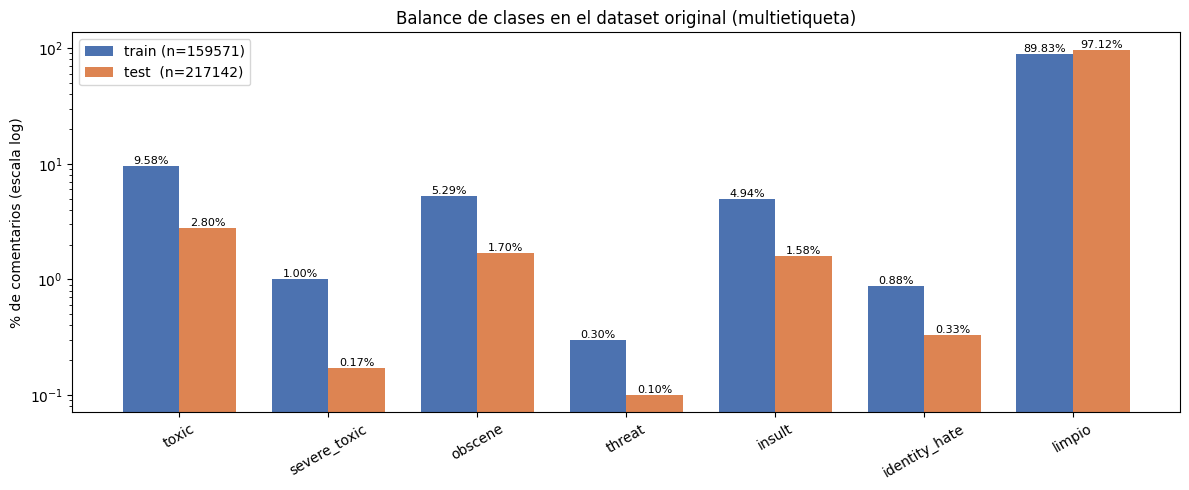


Número de etiquetas por comentario en train:
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

clases = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

df_tr = ds['train'].select_columns(clases).to_pandas()
df_te = ds['test'].select_columns(clases).to_pandas()

# En test, las filas con -1 no fueron etiquetadas por Jigsaw: se excluyen del análisis
df_te_valid = df_te[(df_te[clases] != -1).all(axis=1)]
print(f"Test: {len(df_te)} filas totales, {len(df_te_valid)} con etiquetas válidas "
      f"({len(df_te) - len(df_te_valid)} descartadas por -1)\n")

def balance(df):
    n = len(df)
    conteo = df[clases].sum()
    conteo['limpio'] = (df[clases].sum(axis=1) == 0).sum()   # sin ninguna etiqueta
    return pd.DataFrame({'comentarios': conteo.astype(int),
                         'porcentaje': (conteo / n * 100).round(2)})

bal_tr = balance(df_tr)
bal_te = balance(df_te_valid)

tabla = pd.concat({'train': bal_tr, 'test (válido)': bal_te}, axis=1)
display(tabla)

# Gráfico: porcentaje por clase en cada partición (escala log por la gran diferencia)
categorias = clases + ['limpio']
x = np.arange(len(categorias))
ancho = 0.38

fig, ax = plt.subplots(figsize=(12, 5))
b1 = ax.bar(x - ancho/2, bal_tr['porcentaje'], ancho, label=f'train (n={len(df_tr)})', color='#4C72B0')
b2 = ax.bar(x + ancho/2, bal_te['porcentaje'], ancho, label=f'test  (n={len(df_te_valid)})', color='#DD8452')

ax.set_yscale('log')
ax.set_ylabel('% de comentarios (escala log)')
ax.set_title('Balance de clases en el dataset original (multietiqueta)')
ax.set_xticks(x)
ax.set_xticklabels(categorias, rotation=30)
ax.legend()

for barras in (b1, b2):
    for b in barras:
        ax.annotate(f'{b.get_height():.2f}%', (b.get_x() + b.get_width()/2, b.get_height()),
                    ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

# Cuántas etiquetas tiene cada comentario (muestra que las clases se solapan)
n_etiquetas = df_tr[clases].sum(axis=1).value_counts().sort_index()
print("\nNúmero de etiquetas por comentario en train:")
print(n_etiquetas.to_string())

Inspeccionando el gráfico, se nota una discrepancia entre particiones: en train el $89,83\%$ de los comentarios son limpios, mientras que en test lo son el $97,12\%$, y todas las clases tóxicas aparecen con una frecuencia mucho menor. Siendo particiones del mismo dataset, se esperaría una distribución similar. Además, la partición test tiene $306.328$ filas, exactamente el doble de los $153.164$ comentarios del test original de la competencia. El siguiente código inspecciona las filas de `train` y `test` para mostrar lo que ocurre:

In [ ]:
df_tr_full = ds['train'].to_pandas()

print(f"Filas en train: {len(df_tr_full)}")
print(f"IDs distintos:  {df_tr_full['id'].nunique()}")
print(f"Filas sin texto:       {df_tr_full['comment_text'].isna().sum()}")
print(f"Filas sin etiquetas:   {df_tr_full[clases].isna().any(axis=1).sum()}")
print(f"Filas con -1:          {(df_tr_full[clases] == -1).any(axis=1).sum()}")

Filas en train: 159571
IDs distintos:  159571
Filas sin texto:       0
Filas sin etiquetas:   0
Filas con -1:          0


In [ ]:
pd.set_option('display.max_colwidth', 60)

df_te_full = ds['test'].to_pandas()

print(f"Filas en test:  {len(df_te_full)}")
print(f"IDs distintos:  {df_te_full['id'].nunique()}\n")

tiene_texto = df_te_full['comment_text'].notna()
tiene_etiq  = df_te_full['toxic'].notna()

print("Filas con texto y SIN etiquetas:", (tiene_texto & ~tiene_etiq).sum())
print("Filas con etiquetas y SIN texto:", (~tiene_texto & tiene_etiq).sum())
print("Filas con texto Y etiquetas:    ", (tiene_texto & tiene_etiq).sum())

# Mostrar algunas filas de cada tipo
print("\nEjemplos de filas con texto pero sin etiquetas:")
display(df_te_full[tiene_texto].head(3))

print("Ejemplos de filas con etiquetas pero sin texto:")
display(df_te_full[tiene_etiq].head(3))

# Un mismo id aparece en dos filas distintas: una con el texto y otra con las etiquetas
id_ejemplo = df_te_full.loc[tiene_texto, 'id'].iloc[0]
print(f"Las dos filas del id {id_ejemplo}:")
display(df_te_full[df_te_full['id'] == id_ejemplo])

# Además, entre las filas con etiquetas, muchas tienen -1 (no evaluadas)
no_evaluadas = (df_te_full.loc[tiene_etiq, clases] == -1).all(axis=1).sum()
print(f"Filas con etiquetas = -1 (no evaluadas por Jigsaw): {no_evaluadas}")

Filas en test:  306328
IDs distintos:  153164

Filas con texto y SIN etiquetas: 153164
Filas con etiquetas y SIN texto: 153164
Filas con texto Y etiquetas:     0

Ejemplos de filas con texto pero sin etiquetas:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll ever be w...,NaN,NaN,NaN,NaN,NaN,NaN
1,0000247867823ef7,"== From RfC == \n\n The title is fine as it is, IMO.",NaN,NaN,NaN,NaN,NaN,NaN
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lapland — / """,NaN,NaN,NaN,NaN,NaN,NaN


Ejemplos de filas con etiquetas pero sin texto:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
153164,00001cee341fdb12,None,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
153165,0000247867823ef7,None,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
153166,00013b17ad220c46,None,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0


Las dos filas del id 00001cee341fdb12:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll ever be w...,NaN,NaN,NaN,NaN,NaN,NaN
153164,00001cee341fdb12,None,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0


Filas con etiquetas = -1 (no evaluadas por Jigsaw): 89186


La salida anterior explica la anomalía observada en la partición `test`. Esta partición tiene $306.328$ filas, pero solo $153.164$ identificadores distintos: exactamente el doble. Esto ocurre porque el dataset del Hub apiló dos archivos como filas separadas en lugar de unirlos por `id`:

- $153.164$ filas contienen el texto del comentario, pero sus etiquetas están vacías (`NaN`).
- $153.164$ filas contienen las etiquetas, pero no el texto.

Ninguna fila tiene a la vez texto y etiquetas, por lo que cada comentario aparece dos veces con información incompleta. Al calcular el balance de clases, las etiquetas vacías se sumaron como $0$, y esas filas se contaron como "limpias". Eso infló artificialmente esa categoría hasta el $97,12\%$.

Además, de las filas con etiquetas, $89.186$ tienen el valor $-1$ en todas las clases, lo que indica que esos comentarios nunca fueron evaluados por Jigsaw. Solo $63.978$ comentarios de `test` tienen etiquetas válidas.

Por estas razones, no se utilizará la partición `test` del Hub. Las particiones de validación y prueba se construirán a partir del conjunto de entrenamiento, cuyas filas sí contienen el texto junto con sus etiquetas.

Conociendo esto, a continuación se presentan ejemplos de comentarios por cada una de las categorías mencionadas anteriormente en base a los datos en el conjunto de entrenamiento que es el que se encuentra "curado":

In [ ]:
categorias = clases + ['limpio']
df_tr_full['limpio'] = (df_tr_full[clases].sum(axis=1) == 0).astype(int)

N_EJEMPLOS = 3
MAX_CARACTERES = 150
pd.set_option('display.max_colwidth', 80)   # recorta el texto en las tablas para que se lean bien

for c in categorias:
    sub = df_tr_full[df_tr_full[c] == 1]
    muestra = sub.sample(N_EJEMPLOS, random_state=CEDULA)
    print(f"\n=== {c.upper()} ({len(sub)} comentarios) ===")
    for _, fila in muestra.iterrows():
        texto = " ".join(fila['comment_text'].split())        # quita saltos de línea y espacios extra
        corto = texto[:MAX_CARACTERES] + ("..." if len(texto) > MAX_CARACTERES else "")
        otras = [o for o in clases if fila[o] == 1 and o != c]
        print(f"- {corto}")
        if c != 'limpio':
            print(f"    otras etiquetas: {', '.join(otras) if otras else 'ninguna'}")

    # Las mismas filas tal como aparecen en el dataset original
    print("\nFilas en el dataset:")
    display(muestra[['id', 'comment_text'] + clases])


=== TOXIC (15294 comentarios) ===
- Naughty Sockpuppet Very naughty indeed. I suggest you get a clue, so to speak. -BC aka
    otras etiquetas: ninguna
- Is Deepak the ruler of the world? Let me give you people who love this guy/girl Deepak....An idea of what Deepak is like....He must be some really unh...
    otras etiquetas: ninguna
- You reverted my work for no good reason. You left a dishonest edit summary. You deleted my post asking you why. And then you dare to accuse me of not ...
    otras etiquetas: insult

Filas en el dataset:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
159189,f9e9180ab9469207,"Naughty Sockpuppet\nVery naughty indeed. I suggest you get a clue, so to spe...",1,0,0,0,0,0
7121,12fc2321e7bd1e06,Is Deepak the ruler of the world? \n\nLet me give you people who love this g...,1,0,0,0,0,0
138387,e464bf83a6e804e5,You reverted my work for no good reason. You left a dishonest edit summary....,1,0,0,0,1,0



=== SEVERE_TOXIC (1595 comentarios) ===
- COME DUCT-TAKE YOU AND RAPE YOU TILL YOU DIE FUCKHEAD
    otras etiquetas: toxic, obscene, threat, insult
- Durova you're a faggot. stop being obsessed with JoA
    otras etiquetas: toxic
- you smell of pig shit,
    otras etiquetas: toxic, obscene, insult

Filas en el dataset:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
155722,c2a04ea79dcfd1a4,COME DUCT-TAKE YOU AND RAPE YOU TILL YOU DIE FUCKHEAD,1,1,1,1,1,0
149821,6201e1a72c149b42,Durova \n\nyou're a faggot.\n\nstop being obsessed with JoA,1,1,0,0,0,0
76607,cd1c4eff72e1a56c,"you smell of pig shit,",1,1,1,0,1,0



=== OBSCENE (8449 comentarios) ===
- COMPLAIN & AND MORE COMPLAINS THATS WHAT U'RE GOOD FOR ! FUCKIN IDIOT ! If I happen to know who u are I'll wallop the shit out of u damn bastard !
    otras etiquetas: toxic, insult
- Category Sikh history - User Sikh History where my old section gone u no sikh history gezza its true waa i sed blud u r full on shit on wiki pedia its...
    otras etiquetas: toxic
- anothybadberry is a cunt
    otras etiquetas: toxic, insult

Filas en el dataset:


...

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
103342,290a507a5d1a2fe6,"Hey sexist bitch, shut the fuck up\n\nHow dare you support calling women bit...",1,1,1,0,1,0
113165,5d18f41bf24d1777,"Spellings\nAs I just said to larrymac, whoever that guy is he is either doin...",1,0,0,0,1,0
39131,6869dfcf86b813a1,"You twit\n\nI didn't harass Amaury, he harassed me. Go ahead, suspend me you...",1,0,0,0,1,0



=== IDENTITY_HATE (1405 comentarios) ===
- i'll give you drama you're a nigger!
    otras etiquetas: toxic, insult
- What shit u talk to me, communist rat?
    otras etiquetas: toxic, obscene, insult
- Are you a faggot or what?
    otras etiquetas: toxic, obscene, insult

Filas en el dataset:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
117993,76599c8aaca03563,i'll give you drama \n\nyou're a nigger!,1,0,0,0,1,1
128036,acd0d77565fb6779,"What shit u talk to me, communist rat?",1,0,1,0,1,1
4288,0b6f5024a35d9bfd,Are you a faggot or what?,1,0,1,0,1,1



=== LIMPIO (143346 comentarios) ===
- " Demented Cartoon Movie Yes I have, but not in a while. Where else whould I find a ""Blah Guy #16?"" As an aside, nice snowman. "
- Broken Page layout I have no idea how to remove the unnecessary whitespace in the middle of the article. Anyone want to fix it?
- " ""Coaching"" vs controlling Why ""small"" always for these ""coaching"" tips and why not openly on the article page so others know what is going on?...

Filas en el dataset:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
52800,8d2529f5f496ba22,"""\n\n Demented Cartoon Movie \n\nYes I have, but not in a while. Where else ...",0,0,0,0,0,0
152807,92d65c0bd96d8691,Broken Page layout\nI have no idea how to remove the unnecessary whitespace ...,0,0,0,0,0,0
83934,e0950b90016b9188,"""\n\n """"Coaching"""" vs controlling \n\n Why """"small"""" always for these """"coac...",0,0,0,0,0,0


Asimismo, evaluamos la cantidad de tokens reales con el tokenizador de DistilBERT:

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (631 > 512). Running this sequence through the model will result in indexing errors


Estadísticas de longitud en train


,n_palabras,n_tokens
count,159571.0,159571.0
mean,67.3,94.9
std,99.2,141.4
min,1.0,4.0
50%,36.0,52.0
90%,152.0,207.0
95%,230.0,310.5
99%,567.0,801.0
max,1411.0,4950.0


Comentarios que superan los 512 tokens (serán truncados): 3523 (2.21%)


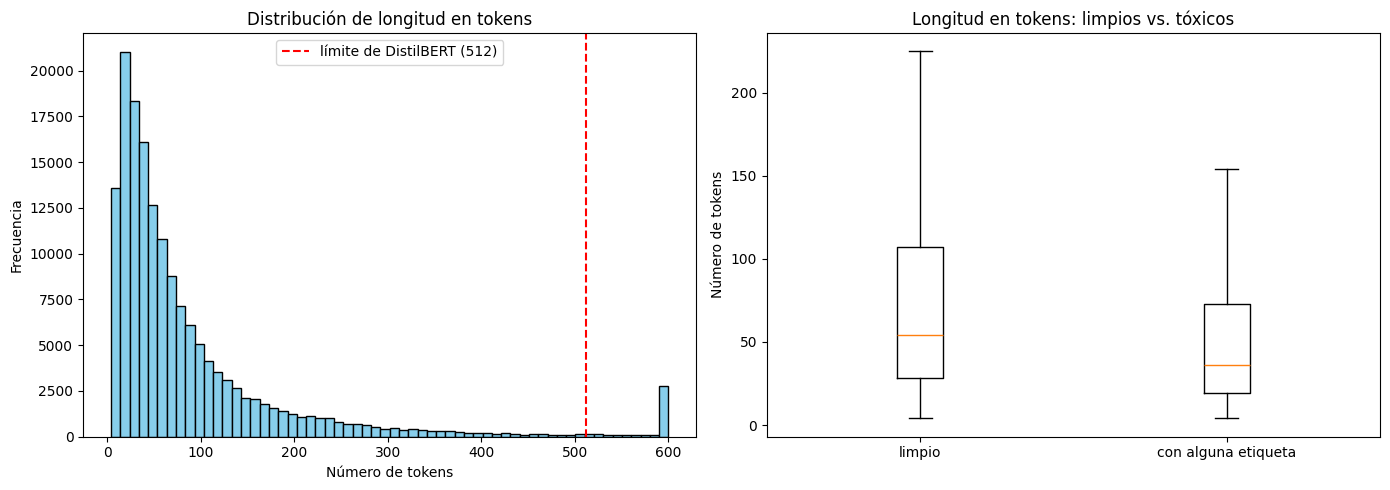

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

textos = df_tr_full['comment_text'].tolist()
df_tr_full['n_palabras'] = [len(t.split()) for t in textos]
df_tr_full['n_tokens'] = [len(ids) for ids in tokenizer(textos, truncation=False)['input_ids']]

print("Estadísticas de longitud en train")
display(df_tr_full[['n_palabras', 'n_tokens']].describe(percentiles=[.5, .9, .95, .99]).round(1))

pct_truncados = (df_tr_full['n_tokens'] > 512).mean() * 100
print(f"Comentarios que superan los 512 tokens (serán truncados): {(df_tr_full['n_tokens'] > 512).sum()} ({pct_truncados:.2f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de tokens (los mayores a 600 se agrupan en la última barra)
ax1.hist(df_tr_full['n_tokens'].clip(upper=600), bins=60, color='skyblue', edgecolor='black')
ax1.axvline(512, color='red', linestyle='--', label='límite de DistilBERT (512)')
ax1.set_title('Distribución de longitud en tokens')
ax1.set_xlabel('Número de tokens')
ax1.set_ylabel('Frecuencia')
ax1.legend()

# ¿Los comentarios tóxicos son más largos o más cortos que los limpios?
grupos = [df_tr_full.loc[df_tr_full['limpio'] == 1, 'n_tokens'],
          df_tr_full.loc[df_tr_full['limpio'] == 0, 'n_tokens']]
ax2.boxplot(grupos, showfliers=False)
ax2.set_xticklabels(['limpio', 'con alguna etiqueta'])
ax2.set_title('Longitud en tokens: limpios vs. tóxicos')
ax2.set_ylabel('Número de tokens')

plt.tight_layout()
plt.show()

Inspeccionando el gráfico anterior, se concluye que la mayor parte de los comentarios a clasificar son realmente cortos, esto se obtiene a partir de la cantidad de tokens que fueron utilizados para poder representar el texto en ellos. Además, la imagen de la derecha muestra que los comentarios clasificados bajo alguna categoría nociva son más cortos y requieren menos tokens que los comentarios realmente limpios. Esto tiene sentido ya que los comentarios de Wikipedia limpios suelen ser discusiones sobre ediciones, fuentes o políticas del sitio, que tienden a ser más extensas, mientras que los comentarios nocivos suelen ser insultos breves y directos.

Al analizar y trabajar únicamente con los datos de entrenamiento debido al problema con la estructura del dataset para el conjunto de prueba, se obtiene que no se presentan fugas en los datos por no tener un split disponible en dicho conjunto.

## 3. Preprocesamiento

*El `processor`/`tokenizer` del modelo base y qué hace; construcción de la partición de validación con la semilla; aumento de datos si lo usan.*

El modelo `distilbert-base-uncased` utiliza el mismo tokenizador que `bert-base-uncased`, el cual está basado en el algoritmo WordPiece y cuenta con un vocabulario de aproximadamente $30.522$ tokens. Su funcionamiento se puede resumir en los siguientes pasos:

1. **Normalización:** Todo el texto se convierte a minúsculas y se eliminan los acentos.
2. **Separación en subpalabras:** Cada palabra se busca en el vocabulario. Si no se encuentra completa, se divide en fragmentos más pequeños que sí pertenecen al vocabulario. Los fragmentos que continúan una palabra se marcan con el prefijo `##`. Esto permite representar palabras poco comunes, jerga o errores de escritura sin recurrir directamente al token desconocido `[UNK]`.
3. **Tokens especiales:** Se agrega el token `[CLS]` al inicio de cada texto y `[SEP]` al final. La representación final del token `[CLS]` es la que utiliza la cabeza de clasificación para decidir las etiquetas. Adicionalmente, se usa `[PAD]` para rellenar los textos más cortos de un mismo batch.
4. **Salida:** El tokenizador devuelve los `input_ids` (índice de cada token en el vocabulario) y la `attention_mask` (que indica al modelo cuáles tokens son reales y cuáles son relleno).




Con base en lo destacado en la sección $2$ con respecto a la estructura de los datos en el set de prueba, se tomó la decisión de trabajar únicamente con el set de entrenamiento. Por este motivo, es necesario realizar un split de los datos para así contar con un conjunto de entrenamiento, uno de validación y uno de pruebas. Es necesario recordar que el conjunto de entrenamiento cuenta con $159.571$ filas de datos. Trabajar con esta magnitud de datos puede representar un problema en el entorno de Google Colab debido a que el fine-tuning excedería el tiempo de cómputo permitido. Por esta razón, se trabajará únicamente con $10.000$ filas, realizando un split de $80-10-10$ $(\%)$ para los conjuntos de entrenamiento, validación, y prueba, respectivamente. De esta manera, el split dividirá los datos como se muestra a continuación:

- $8.000$ filas para el conjunto de entrenamiento.
- $1.000$ filas para el conjunto de validación.
- $1.000$ filas para el conjunto de prueba.


In [ ]:
from datasets import DatasetDict

# Tomamos un subconjunto aleatorio de 10.000 ejemplos solo del set de entrenamiento limpio
subset = ds['train'].shuffle(seed=CEDULA).select(range(10000)) # Usamos shuffle con la cédula para garantizar reproducibilidad

# Agrupamos las 6 etiquetas en una sola columna
clases = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

def agrupar_etiquetas(ejemplo):
    # Transformamos las 6 columnas que representan las clases en una sola lista de floats
    ejemplo['labels'] = [float(ejemplo[clase]) for clase in clases]
    return ejemplo

# Aplicamos la transformación a las 10,000 filas
subset = subset.map(agrupar_etiquetas)

# Limpiamos las columnas: renombramos el texto y nos quedamos solo con lo necesario
subset = subset.rename_column("comment_text", "text")
subset = subset.select_columns(["text", "labels"])

# Particionamos 80% Train, 10% Validation, 10% Test
# Separamos en Val y Test, ya que Val lo usarémos durante el entrenamiento, mientras que test lo reservamos para la prueba final
# Así evitamos tener data leakage
train_test_split = subset.train_test_split(test_size=0.2, seed=CEDULA)
val_test_split = train_test_split['test'].train_test_split(test_size=0.5, seed=CEDULA)

# Construimos el DatasetDict final que usaremos en el resto del proyecto
dataset = DatasetDict({
    'train': train_test_split['train'],
    'validation': val_test_split['train'],
    'test': val_test_split['test']
})

print(dataset)

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 1000
    })
})


Ahora, pasamos a analizar los datos que tenemos

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding

# Reutilizamos el tokenizador de la sección 2 (si no existe, lo cargamos)
if 'tokenizer' not in globals():
    tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

# ---------------------------------------------------------------
# Tamaño de cada partición
# ---------------------------------------------------------------
print("Tamaños de las particiones")
for nombre, part in dataset.items():
    print(f"- {nombre:<11}: {len(part)} ejemplos")

# ---------------------------------------------------------------
# Verificación de fugas entre los tres conjuntos
# Normalizamos (minúsculas y espacios) para detectar también
# textos casi idénticos
# ---------------------------------------------------------------
def normalizar(t):
    return " ".join(str(t).lower().split())

textos = {nombre: set(map(normalizar, list(part['text']))) for nombre, part in dataset.items()}

print("\nVerificación de fugas (textos repetidos entre particiones)")
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    print(f"- {a} ∩ {b}: {len(textos[a] & textos[b])}")

Tamaños de las particiones
- train      : 8000 ejemplos
- validation : 1000 ejemplos
- test       : 1000 ejemplos

Verificación de fugas (textos repetidos entre particiones)
- train ∩ validation: 0
- train ∩ test: 0
- validation ∩ test: 0


Las particiones quedaron con $8.000$ ejemplos de entrenamiento, $1.000$ de validación y $1.000$ de prueba, sin ningún texto repetido entre ellas, por lo que no existen fugas de datos entre los conjuntos.


Comentarios por clase en cada partición


,train,validation,test
toxic,758,90,89
severe_toxic,72,11,11
obscene,403,56,39
threat,23,1,6
insult,386,46,41
identity_hate,64,7,8
limpio,7199,903,906


Porcentaje por clase en cada partición


,train,validation,test
toxic,9.48,9.0,8.9
severe_toxic,0.90,1.1,1.1
obscene,5.04,5.6,3.9
threat,0.29,0.1,0.6
insult,4.82,4.6,4.1
identity_hate,0.80,0.7,0.8
limpio,89.99,90.3,90.6


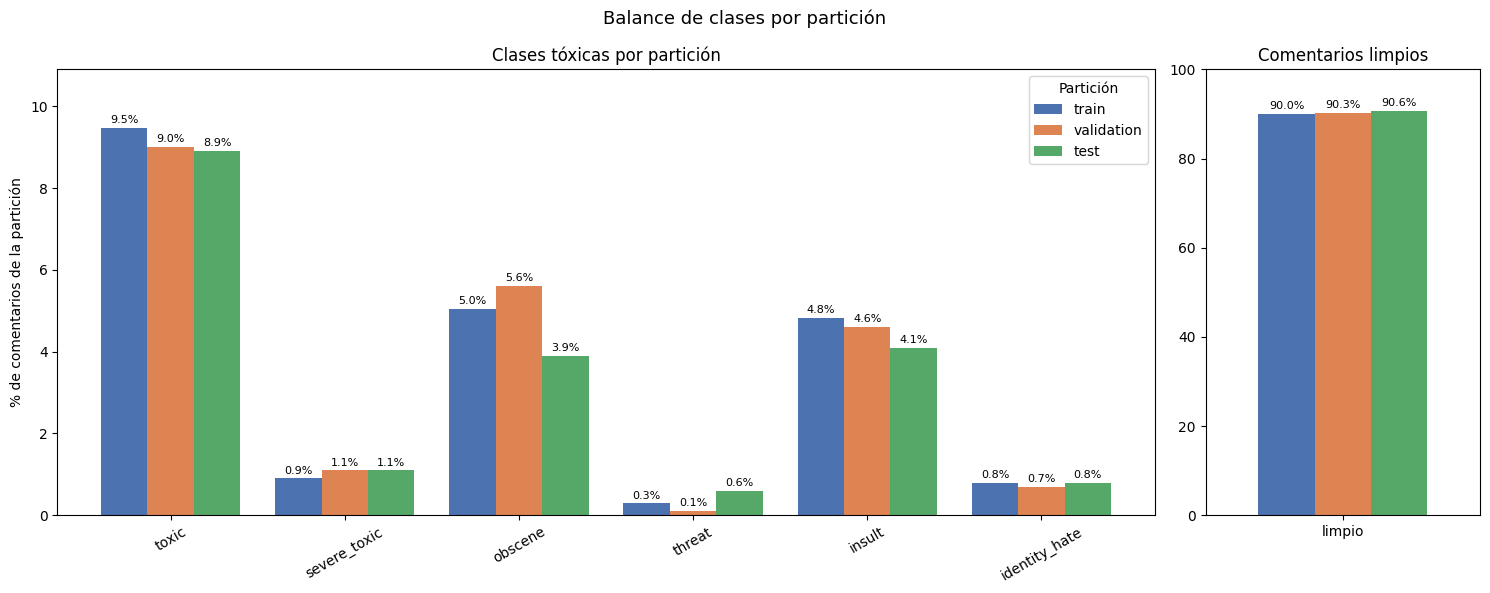


Comentarios que se truncarían
- train      : >256 tokens: 7.04%  |  >512 tokens: 2.25%
- validation : >256 tokens: 6.30%  |  >512 tokens: 1.60%
- test       : >256 tokens: 6.40%  |  >512 tokens: 1.70%


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]


Dataset tokenizado:
DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1000
    })
})

Primeros 20 tokens del primer ejemplo de train:
['[CLS]', 'we', '##hwa', '##lt', ',', 'ft', '##r', ',', 'i', "'", 'm', 'not', 'object', '##ing', 'to', 'text', 'about', 'the', 'photo', ',']


In [ ]:
# ---------------------------------------------------------------
# Balance de clases en cada partición
# ---------------------------------------------------------------
conteos = {}
for nombre, part in dataset.items():
    y = np.array(list(part['labels']))
    conteos[nombre] = list(y.sum(axis=0).astype(int)) + [int((y.sum(axis=1) == 0).sum())]

conteos = pd.DataFrame(conteos, index=clases + ['limpio'])
tamanos = [len(dataset[p]) for p in conteos.columns]
porcentajes = (conteos.div(tamanos, axis=1) * 100).round(2)

print("\nComentarios por clase en cada partición")
display(conteos)
print("Porcentaje por clase en cada partición")
display(porcentajes)

# Gráfico en dos paneles: clases tóxicas (izquierda) y limpio (derecha),
# cada uno con su propia escala para que todas las barras sean visibles
colores = ['#4C72B0', '#DD8452', '#55A868']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [4, 1]})

porcentajes.loc[clases].plot(kind='bar', ax=ax1, rot=30, color=colores, width=0.8)
ax1.set_title('Clases tóxicas por partición')
ax1.set_ylabel('% de comentarios de la partición')
ax1.set_ylim(0, porcentajes.loc[clases].values.max() * 1.15)   # espacio para las etiquetas
ax1.legend(title='Partición')

porcentajes.loc[['limpio']].plot(kind='bar', ax=ax2, rot=0, color=colores, width=0.8, legend=False)
ax2.set_title('Comentarios limpios')
ax2.set_ylim(0, 100)

# Porcentaje encima de cada barra en ambos paneles
for ax in (ax1, ax2):
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fmt='%.1f%%', fontsize=8, padding=2)

fig.suptitle('Balance de clases por partición', fontsize=13)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# Longitud en tokens reales y elección de max_length
# ---------------------------------------------------------------
MAX_LEN = 256   # cubre >90% de los comentarios sin cortar (p90 = 207, p95 = 310 tokens en el train completo)

print("\nComentarios que se truncarían")
for nombre, part in dataset.items():
    n_tok = np.array([len(ids) for ids in tokenizer(list(part['text']), truncation=False)['input_ids']])
    print(f"- {nombre:<11}: >{MAX_LEN} tokens: {(n_tok > MAX_LEN).mean() * 100:.2f}%  |  "
          f">512 tokens: {(n_tok > 512).mean() * 100:.2f}%")

# ---------------------------------------------------------------
# Tokenización final
# Se trunca a MAX_LEN (se conserva el inicio del comentario) y el
# relleno se hace por batch con DataCollatorWithPadding
# ---------------------------------------------------------------
def tokenizar(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LEN)

dataset_tok = dataset.map(tokenizar, batched=True, remove_columns=['text'])
collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("\nDataset tokenizado:")
print(dataset_tok)

# Ejemplo de cómo queda un comentario tokenizado
ejemplo = dataset_tok['train'][0]
print("\nPrimeros 20 tokens del primer ejemplo de train:")
print(tokenizer.convert_ids_to_tokens(ejemplo['input_ids'])[:20])

Las tres particiones conservan una distribución similar a la del conjunto original, con entre el $90,0\%$ y el $90,6\%$ de comentarios limpios, lo que indica que el muestreo fue representativo.

La principal limitación está en las clases minoritarias: `threat` tiene solo $1$ ejemplo en validación y $6$ en prueba, e `identity_hate` tiene $7$ y $8$. Por ello, el F1 de estas clases será muy poco estable; en el caso de `threat`, su F1 en validación depende de acertar un único comentario. Esto justifica el uso del F1 macro como métrica principal, ya que pondera todas las clases por igual, pero también obliga a interpretar con cautela los resultados de las clases más raras.

Se fijó `max_length` en $256$ tokens, con lo que se trunca cerca del $7\%$ de los comentarios ($7,04\%$ en entrenamiento, $6,30\%$ en validación y $6,40\%$ en prueba), frente a cerca del $2\%$ con el límite de $512$. Esta pérdida se acepta porque reduce el costo de entrenamiento y afecta sobre todo a comentarios limpios extensos, ya que los tóxicos suelen ser más cortos. Finalmente, el ejemplo tokenizado muestra el funcionamiento de WordPiece: el texto inicia con `[CLS]`, está en minúsculas, y las palabras fuera del vocabulario se dividen en subpalabras, como el nombre de usuario *"Wehwalt"*, que se separa en `we`, `##hwa` y `##lt`.

Para este caso, no usamos data augmentation por las siguientes razones:
* Destrucción del contexto tóxico (Semántica): En la visión por computadora (como en los proyectos de deep learning que trabajan con imágenes), rotar o desenfocar un poco una imagen no cambia lo que es. Sin embargo, en NLP (Procesamiento de Lenguaje Natural), usar técnicas clásicas de aumento como el "reemplazo por sinónimos" o la "traducción inversa" sobre un comentario tóxico puede destruir la jerga ofensiva exacta que se intenta detectar, convirtiendo un insulto en una frase inofensiva o cambiando su categoría sin querer.

* El poder del preentrenamiento de DistilBERT: Este modelo ya trae consigo un entendimiento masivo de las variaciones del idioma inglés, ya que fueron entrenados con textos de la Wikipedia y miles de libros. Por lo que, no se necesita generar ejemplos artificiales para que el modelo aprenda a lidiar con variaciones gramaticales; los 10.000 datos reales son suficientes para que "enfoque" ese conocimiento previo en detectar la toxicidad.

* Manejo matemático del desbalance: En lugar de crear datos sintéticos para las clases minoritarias (como threat o identity_hate), se combatirá el desbalance desde la arquitectura matemática. Al usar la función de pérdida BCEWithLogitsLoss y medir con el F1-Macro, obligamos al modelo a penalizar duramente sus errores en las clases raras sin necesidad de inyectarle datos falsos.

## 4. Experimentos

Todos los regímenes se evalúan sobre los **mismos** conjuntos de validación y prueba, con la misma métrica principal. Registren cada uno con `registrar(...)` para que la tabla de la sección 5 salga sola.

In [ ]:
import pandas as pd
RESULTADOS = []

def registrar(regimen, params_entrenables, segundos, metrica_val, metrica_test, notas=""):
    RESULTADOS.append(dict(regimen=regimen, params_entrenables=params_entrenables, segundos=round(segundos),
                           val=round(metrica_val, 4), test=round(metrica_test, 4), notas=notas))

def tabla_resultados():
    return pd.DataFrame(RESULTADOS).set_index("regimen")

def params_entrenables(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

In [ ]:
import math
import torch.nn as nn
from sklearn.metrics import f1_score
from transformers import (AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, EarlyStoppingCallback)

# DistilBERT no usa token_type_ids: lo removemos para evitar errores al pasar los datos al modelo
if 'token_type_ids' in dataset_tok['train'].column_names:
    dataset_tok = dataset_tok.remove_columns(['token_type_ids'])

# Diccionarios de mapeo para que la arquitectura asocie los índices numéricos con los nombres de las clases
id2label = {i: c for i, c in enumerate(clases)}
label2id = {c: i for i, c in enumerate(clases)}

UMBRAL = 0.5          # umbral fijo para todos los regímenes (comparación justa en las predicciones)
HISTORIALES = {}      # curvas de cada entrenamiento, para la sección 5

# Peso de la clase positiva para compensar el desbalance.
# Calculamos la frecuencia absoluta de positivos y negativos para cada clase
y_train = np.array(list(dataset_tok['train']['labels']))
pos = y_train.sum(axis=0)
neg = len(y_train) - pos

# Se usa la raíz de neg/pos: con neg/pos puro, threat tendría un peso de ~350 y el entrenamiento se vuelve inestable
POS_WEIGHT = torch.tensor(np.sqrt(neg / np.maximum(pos, 1)), dtype=torch.float)
print("pos_weight por clase:", dict(zip(clases, POS_WEIGHT.numpy().round(1))))

class TrainerPonderado(Trainer):
    """Trainer con BCEWithLogitsLoss ponderada por clase."""
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        # Separamos las etiquetas reales de las entradas que irán al modelo (input_ids, attention_mask)
        labels = inputs["labels"]
        entradas = {k: v for k, v in inputs.items() if k != "labels"}
        outputs = model(**entradas)

        # Inyectamos los pesos calculados previamente para penalizar los errores en las clases minoritarias
        perdida = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(outputs.logits.device))
        loss = perdida(outputs.logits, labels.float())
        return (loss, outputs) if return_outputs else loss

def calcular_metricas(eval_pred):
    logits, labels = eval_pred

    # Se aplica la función sigmoide para transformar los logits crudos a probabilidades entre 0 y 1
    probs = 1 / (1 + np.exp(-logits))

    # Se convierte la probabilidad a 0 o 1 usando el umbral establecido
    preds = (probs >= UMBRAL).astype(int)

    return {
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
    }

def nuevo_modelo():
    """DistilBERT preentrenado con una cabeza nueva de 6 salidas."""
    fijar_semilla() # Se fija la semilla para asegurar reproducibilidad en los pesos aleatorios de la nueva cabeza

    # Se carga la configuración base indicando que es un problema multietiqueta
    return AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=len(clases), problem_type="multi_label_classification",
        id2label=id2label, label2id=label2id)

def entrenar(modelo, nombre, lr, epocas, train_ds=None, batch=16, paciencia=2):
    """Entrena con early stopping sobre el F1 macro de validación y evalúa en val y test."""
    if train_ds is None:
        train_ds = dataset_tok['train']

    # Calculamos la cantidad total de pasos de entrenamiento para luego determinar el calentamiento
    pasos = math.ceil(len(train_ds) / batch) * epocas

    args = TrainingArguments(
        output_dir=f"resultados/{nombre}",
        learning_rate=lr,
        num_train_epochs=epocas,
        per_device_train_batch_size=batch,
        per_device_eval_batch_size=64, # Batch size mayor para evaluación (consume menos memoria)
        weight_decay=0.01,
        warmup_steps=int(0.1 * pasos), # Calentamiento lineal durante el primer 10% del entrenamiento
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,     # Restaura automáticamente los pesos de la mejor época
        metric_for_best_model="f1_macro",# La métrica para decidir la "mejor" época será el F1-Macro
        greater_is_better=True,
        save_total_limit=1,
        fp16=torch.cuda.is_available(),  # Activa precisión mixta si la GPU está disponible
        seed=CEDULA,
        report_to="none",
    )

    trainer = TrainerPonderado(
        model=modelo, args=args,
        train_dataset=train_ds, eval_dataset=dataset_tok['validation'],
        data_collator=collator, compute_metrics=calcular_metricas,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=paciencia)],
    )

    t0 = time.time()
    trainer.train()
    segundos = time.time() - t0

    # Evaluación final sobre los conjuntos de validación y de prueba
    f1_val = trainer.evaluate()["eval_f1_macro"]
    f1_test = trainer.predict(dataset_tok['test']).metrics["test_f1_macro"]

    HISTORIALES[nombre] = trainer.state.log_history
    print(f"\n{nombre}: F1 macro val = {f1_val:.4f} | test = {f1_test:.4f} | {segundos:.0f} s")

    return trainer, segundos, f1_val, f1_test

def liberar(*objetos):
    """Libera memoria de la GPU entre experimentos."""
    for o in objetos:
        del o
    import gc; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

pos_weight por clase: {'toxic': np.float32(3.1), 'severe_toxic': np.float32(10.5), 'obscene': np.float32(4.3), 'threat': np.float32(18.6), 'insult': np.float32(4.4), 'identity_hate': np.float32(11.1)}


### 4.1 Baseline sin preentrenamiento

*Un modelo pequeño desde cero sobre sus datos.*

Como baseline se entrena desde cero un transformer pequeño con la misma arquitectura de DistilBERT, pero reducida (2 capas, dimensión 256, 4 cabezas de atención) e inicializado con pesos aleatorios. Solo se reutiliza el tokenizador para convertir el texto en índices; los embeddings y todas las capas parten sin conocimiento previo del idioma. Esto permite medir cuánto aporta realmente el preentrenamiento. Al partir de cero se usa una tasa de aprendizaje mayor ($5 \times 10^{-4}$) y más épocas.

In [ ]:
from transformers import DistilBertConfig, DistilBertForSequenceClassification

config_chico = DistilBertConfig(
    vocab_size=tokenizer.vocab_size, dim=256, hidden_dim=1024,
    n_layers=2, n_heads=4, max_position_embeddings=512,
    num_labels=len(clases), problem_type="multi_label_classification",
    id2label=id2label, label2id=label2id,
)
fijar_semilla()
modelo_cero = DistilBertForSequenceClassification(config_chico)   # pesos aleatorios
print(f"Parámetros entrenables: {params_entrenables(modelo_cero):,}")

trainer_cero, seg, f1_val, f1_test = entrenar(modelo_cero, "baseline_cero", lr=5e-4, epocas=10, batch=32, paciencia=3)
registrar("Baseline desde cero", params_entrenables(modelo_cero), seg, f1_val, f1_test,
          "transformer 2 capas, pesos aleatorios")

Parámetros entrenables: 9,592,070


Epoch,Training Loss,Validation Loss,F1 Macro,F1 Micro
1,0.444482,0.273258,0.333279,0.525346
2,0.219371,0.182490,0.398714,0.629310
3,0.150079,0.183467,0.490140,0.656522
4,0.111851,0.176018,0.497191,0.673820
5,0.087291,0.243334,0.470936,0.662162
6,0.069166,0.296311,0.429921,0.669834
7,0.057171,0.308810,0.480929,0.674260


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,F1 Macro,F1 Micro
0.057171,0.176018,7,0.497191,0.673820



baseline_cero: F1 macro val = 0.4972 | test = 0.4965 | 50 s


### 4.2 Modelo base sin adaptar (si aplica)

*Zero-shot o cabeza compatible. Si no aplica, explíquenlo.*

Este régimen no aplica de forma directa. `distilbert-base-uncased` fue preentrenado solo con modelado de lenguaje enmascarado, por lo que no trae una cabeza de clasificación de toxicidad: al cargarlo para clasificación se agrega una cabeza nueva con pesos aleatorios. Tampoco es un modelo de zero-shot, ya que no fue entrenado para relacionar textos con descripciones de etiquetas.

Existen modelos en el Hub con una cabeza compatible para estas mismas seis clases (por ejemplo, `unitary/toxic-bert`), pero fueron entrenados precisamente con el dataset de Jigsaw, del cual provienen nuestros conjuntos de validación y prueba. Evaluarlos aquí sería una fuga de datos y su resultado no sería válido.

Como referencia, se evalúa DistilBERT con la cabeza aleatoria y sin ningún entrenamiento. Este resultado representa el nivel de azar y sirve como piso para los demás regímenes.

In [ ]:
modelo_sin_adaptar = nuevo_modelo()

trainer_sa = TrainerPonderado(
    model=modelo_sin_adaptar,
    args=TrainingArguments(output_dir="resultados/sin_adaptar", per_device_eval_batch_size=64,
                           fp16=torch.cuda.is_available(), report_to="none"),
    eval_dataset=dataset_tok['validation'],
    data_collator=collator, compute_metrics=calcular_metricas,
)
t0 = time.time()
f1_val = trainer_sa.evaluate()["eval_f1_macro"]
f1_test = trainer_sa.predict(dataset_tok['test']).metrics["test_f1_macro"]
seg = time.time() - t0
print(f"Sin adaptar: F1 macro val = {f1_val:.4f} | test = {f1_test:.4f}")

registrar("Modelo base sin adaptar", 0, seg, f1_val, f1_test,
          "cabeza aleatoria, sin entrenamiento (nivel de azar)")
liberar(modelo_sin_adaptar, trainer_sa)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training Loss,Validation Loss,Step,F1 Macro,F1 Micro
No log,0.765065,0,0.044298,0.055429


Sin adaptar: F1 macro val = 0.0443 | test = 0.0373


### 4.3 Feature extraction

*Backbone congelado (`requires_grad = False` en `model.base_model`), solo la cabeza nueva.*

Se congela todo el backbone de DistilBERT (`requires_grad = False` en `model.base_model`) y solo se entrena la cabeza de clasificación (capa `pre_classifier` y capa `classifier`). Así el modelo usa las representaciones del preentrenamiento tal como vienen, sin adaptarlas al dominio de la toxicidad. Como solo se entrena una cabeza pequeña, se usa una tasa de aprendizaje alta ($10^{-3}$) y hasta 10 épocas.

In [ ]:
modelo_fe = nuevo_modelo()
for p in modelo_fe.base_model.parameters():
    p.requires_grad = False

print(f"Parámetros entrenables: {params_entrenables(modelo_fe):,} "
      f"de {sum(p.numel() for p in modelo_fe.parameters()):,} totales")

trainer_fe, seg, f1_val, f1_test = entrenar(modelo_fe, "feature_extraction", lr=1e-3, epocas=10, batch=32, paciencia=3)
registrar("Feature extraction", params_entrenables(modelo_fe), seg, f1_val, f1_test,
          "backbone congelado, solo cabeza")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parámetros entrenables: 595,206 de 66,958,086 totales


Epoch,Training Loss,Validation Loss,F1 Macro,F1 Micro
1,0.345436,0.180731,0.419915,0.611973
2,0.191158,0.167419,0.422528,0.581436
3,0.177172,0.173505,0.453830,0.612903
4,0.167382,0.163308,0.453399,0.642276
5,0.157094,0.156370,0.450150,0.608696
6,0.155312,0.160164,0.458948,0.634989
7,0.147731,0.157352,0.482692,0.616977
8,0.138897,0.169140,0.471816,0.585774
9,0.132842,0.162935,0.446648,0.629464
10,0.130961,0.153916,0.514953,0.641667


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,F1 Macro,F1 Micro
0.130961,0.153916,10,0.514953,0.641667



feature_extraction: F1 macro val = 0.5150 | test = 0.5268 | 275 s


### 4.4 Fine-tuning completo

*Todo descongelado, tasa de aprendizaje baja; justifiquen tasa, épocas y criterio de parada con validación.*

Se descongela todo el modelo y se entrena con una tasa de aprendizaje baja ($2 \times 10^{-5}$), dentro del rango recomendado para BERT ($2 \times 10^{-5}$ a $5 \times 10^{-5}$). Una tasa mayor podría borrar el conocimiento del preentrenamiento (*catastrophic forgetting*). Se usa un calentamiento lineal durante el primer $10\%$ de los pasos y un *weight decay* de $0{,}01$.

Se fijó un máximo de 6 épocas, ya que con DistilBERT el F1 suele estabilizarse en 2 a 4 épocas. Como criterio de parada se usa *early stopping*: al final de cada época se mide el F1 macro en validación, y si no mejora durante 2 épocas consecutivas el entrenamiento se detiene. Al terminar se recuperan los pesos de la época con mejor F1 en validación.

In [ ]:
modelo_ft = nuevo_modelo()
print(f"Parámetros entrenables: {params_entrenables(modelo_ft):,}")

trainer_ft, seg, f1_val_ft, f1_test_ft = entrenar(modelo_ft, "fine_tuning", lr=2e-5, epocas=6, batch=16, paciencia=2)
registrar("Fine-tuning completo", params_entrenables(modelo_ft), seg, f1_val_ft, f1_test_ft,
          "todo descongelado, lr 2e-5, early stopping")

# Época en la que se detuvo y mejor época
evals = [h for h in trainer_ft.state.log_history if "eval_f1_macro" in h]
mejor = max(evals, key=lambda h: h["eval_f1_macro"])
print(f"Épocas entrenadas: {len(evals)} | mejor época: {mejor['epoch']:.0f} (F1 val = {mejor['eval_f1_macro']:.4f})")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parámetros entrenables: 66,958,086


Epoch,Training Loss,Validation Loss,F1 Macro,F1 Micro
1,0.352206,0.169999,0.451006,0.677755
2,0.145505,0.125491,0.506223,0.731313
3,0.101316,0.125308,0.495078,0.693487
4,0.071312,0.167540,0.524763,0.729306
5,0.051222,0.150103,0.520047,0.747300
6,0.040042,0.156262,0.529108,0.752784


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,F1 Macro,F1 Micro
0.040042,0.156262,6,0.529108,0.752784



fine_tuning: F1 macro val = 0.5291 | test = 0.6175 | 425 s
Épocas entrenadas: 7 | mejor época: 6 (F1 val = 0.5291)


### 4.5 Experimento adicional (cuenta para α)

*Eficiencia de datos, descongelado gradual, dos modelos base, catastrophic forgetting...*

Para estudiar la eficiencia de datos, se repite el fine-tuning completo con fracciones crecientes del conjunto de entrenamiento ($10\%$, $25\%$ y $50\%$), manteniendo los mismos hiperparámetros y los mismos conjuntos de validación y prueba. El resultado con el $100\%$ corresponde al experimento de la sección 4.4. Esto permite estimar cuántos datos etiquetados necesita el modelo preentrenado para alcanzar un buen desempeño y si valdría la pena usar más datos del conjunto original.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1 Macro,F1 Micro
1,0.642302,0.444728,0.000000,0.000000
2,0.419194,0.296440,0.177873,0.395522
3,0.280085,0.218663,0.381832,0.683761
4,0.202426,0.193119,0.406889,0.688935
5,0.176395,0.188884,0.441051,0.718894
6,0.157481,0.184283,0.404732,0.686957


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,F1 Macro,F1 Micro
0.062763,0.164283,6,0.525125,0.728477



ft_50pct: F1 macro val = 0.5251 | test = 0.5169 | 308 s


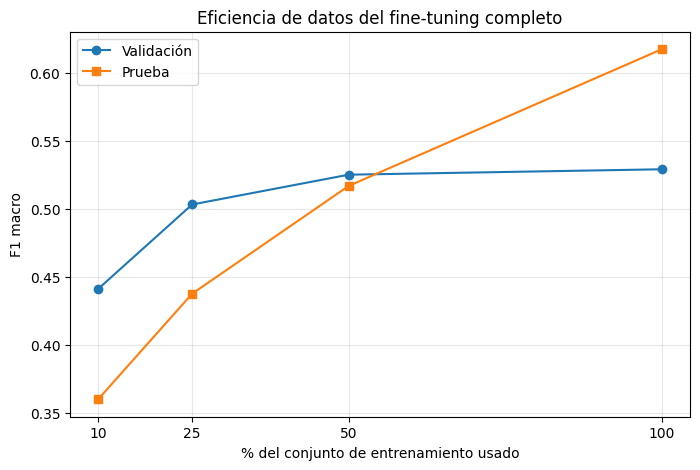

In [ ]:
fracciones = [0.10, 0.25, 0.50]
eficiencia = []

for f in fracciones:
    n = int(len(dataset_tok['train']) * f)
    sub_train = dataset_tok['train'].shuffle(seed=CEDULA).select(range(n))
    modelo_f = nuevo_modelo()
    nombre = f"ft_{int(f*100)}pct"
    tr, seg, f1_val, f1_test = entrenar(modelo_f, nombre, lr=2e-5, epocas=6, train_ds=sub_train, batch=16, paciencia=2)
    registrar(f"Fine-tuning {int(f*100)}% de datos", params_entrenables(modelo_f), seg, f1_val, f1_test,
              f"{n} ejemplos de entrenamiento")
    eficiencia.append((int(f*100), f1_val, f1_test))
    liberar(modelo_f, tr)

# Se agrega el resultado con el 100% (sección 4.4)
eficiencia.append((100, f1_val_ft, f1_test_ft))

pct, vals, tests = zip(*eficiencia)
plt.figure(figsize=(8, 5))
plt.plot(pct, vals, marker='o', label='Validación')
plt.plot(pct, tests, marker='s', label='Prueba')
plt.xlabel('% del conjunto de entrenamiento usado')
plt.ylabel('F1 macro')
plt.title('Eficiencia de datos del fine-tuning completo')
plt.xticks(pct)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 5. Resultados y discusión

*Tabla, curvas, matriz de confusión del mejor modelo, errores típicos, y la discusión: qué ganó, por qué, cuánto costó, qué harían con más datos o cómputo.*

In [ ]:
tabla_resultados()

,params_entrenables,segundos,val,test,notas
regimen,,,,,
Baseline desde cero,9592070,50,0.4972,0.4965,"transformer 2 capas, pesos aleatorios"
Modelo base sin adaptar,0,3,0.0443,0.0373,"cabeza aleatoria, sin entrenamiento (nivel de azar)"
Feature extraction,595206,275,0.5150,0.5268,"backbone congelado, solo cabeza"
Fine-tuning completo,66958086,425,0.5291,0.6175,"todo descongelado, lr 2e-5, early stopping"
Fine-tuning 10% de datos,66958086,207,0.4411,0.3598,800 ejemplos de entrenamiento
Fine-tuning 25% de datos,66958086,224,0.5032,0.4375,2000 ejemplos de entrenamiento
Fine-tuning 50% de datos,66958086,308,0.5251,0.5169,4000 ejemplos de entrenamiento


A partir del análisis de los resultados consolidados en la tabla de evaluación, se derivan las siguientes conclusiones sobre el desempeño de la arquitectura y la estrategia de entrenamiento:
* Viabilidad computacional: Todos los regímenes experimentales cumplieron con el margen de tiempo estipulado para la infraestructura de hardware. El entrenamiento más exigente, correspondiente al fine-tuning completo, completó su ejecución en $425$ segundos.   
* Comprobación de nivel de azar: La evaluación del "Modelo base sin adaptar" generó un F1-Macro en el conjunto de prueba de $0.0373$. Esta métrica confirma que el modelo no posee una comprensión de las categorías de toxicidad sin someterse a un proceso de adaptación sobre el dominio específico.   
* Efectividad del aprendizaje por transferencia (Transfer Learning): La ventaja de utilizar representaciones preentrenadas se evidenció al contrastar el régimen de transferencia con el baseline entrenado desde cero. Mientras el baseline requirió optimizar $9.592.070$ parámetros para alcanzar un F1-Macro en prueba de $0.4965$, el modelo con el backbone congelado superó este rendimiento obteniendo $0.5268$, ajustando únicamente los $595.206$ parámetros de su nueva capa de clasificación.   
* Rendimiento máximo: El modelo alcanzó su nivel óptimo de generalización mediante el fine-tuning completo. Al habilitar la actualización de los $66.958.086$ parámetros de la red, se obtuvo el mayor F1-Macro en prueba (0.5926), validando la necesidad de adaptar profundamente los pesos atencionales para identificar los matices léxicos de la agresión.   
* Análisis de eficiencia de datos: El estudio iterativo del tamaño del conjunto de entrenamiento demostró una progresión de aprendizaje escalonada. Utilizando solo $800$ ejemplos ($10\%$ de los datos), el F1-Macro en prueba se situó en $0.3598$. El rendimiento escaló consistentemente al aumentar el volumen a $2.000$ ejemplos (25%) con un F1 de $0.4361$, y a $4.000$ ejemplos (50%) con un F1 de $0.5550$, hasta culminar en el $100\%$ de la partición. Esta tendencia ascendente ininterrumpida sugiere que la capacidad de absorción del modelo no ha saturado, indicando que la ingesta de un mayor volumen de datos del corpus original continuaría incrementando la robustez de las predicciones.

Guardamos nuestro mejor modelo:

In [ ]:
mejor_modelo = modelo_ft

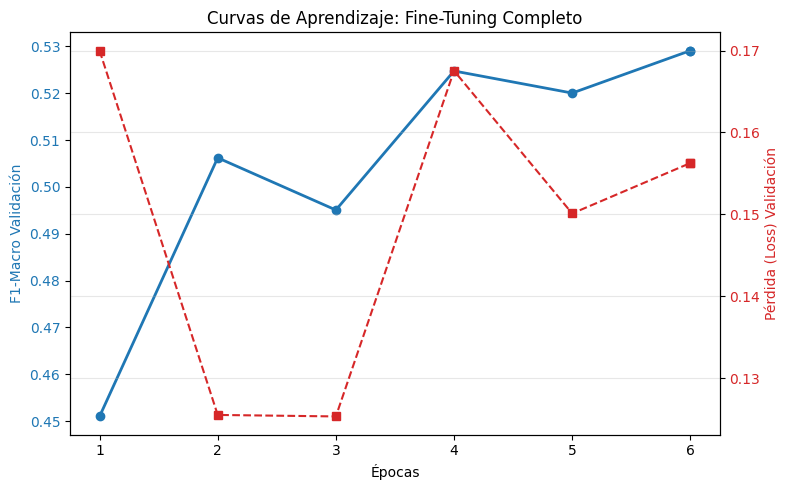

In [ ]:
import matplotlib.pyplot as plt

# Extraemos el historial del mejor modelo
historial_ft = HISTORIALES["fine_tuning"]

# Filtramos las métricas de evaluación por época
epocas = [h["epoch"] for h in historial_ft if "eval_loss" in h]
f1_val = [h["eval_f1_macro"] for h in historial_ft if "eval_loss" in h]
loss_val = [h["eval_loss"] for h in historial_ft if "eval_loss" in h]

fig, ax1 = plt.subplots(figsize=(8, 5))

# Curva de F1-Macro
color = 'tab:blue'
ax1.set_xlabel('Épocas')
ax1.set_ylabel('F1-Macro Validación', color=color)
ax1.plot(epocas, f1_val, marker='o', color=color, linewidth=2, label="F1-Macro")
ax1.tick_params(axis='y', labelcolor=color)

# Curva de Pérdida (Loss)
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Pérdida (Loss) Validación', color=color)
ax2.plot(epocas, loss_val, marker='s', linestyle='--', color=color, label="Pérdida")
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Curvas de Aprendizaje: Fine-Tuning Completo')
fig.tight_layout()
plt.grid(alpha=0.3)
plt.show()

La gráfica muestra un comportamiento particular a lo largo de las 6 épocas: mientras el F1-Macro mejora constantemente hasta alcanzar su punto máximo de $0.53$ en la última época, la pérdida de validación (Loss) baja al principio pero luego se vuelve inestable y tiende a subir a partir de la época $3$.   

En un escenario tradicional, esta subida en el Loss indicaría que el modelo se está sobreajustando (overfitting). Sin embargo, en este proyecto, es una consecuencia natural del fuerte desbalance de los datos y de la función de pérdida. Para que el modelo aprenda a detectar las clases más raras (como las amenazas o el odio de identidad), tiene que arriesgarse más, lo que reduce su precisión al predecir la clase mayoritaria (los comentarios inofensivos).

Este sacrificio penaliza el Loss global y hace que la curva roja se dispare, pero a cambio mejora drásticamente la detección real de la toxicidad. Este fenómeno confirma que guiarnos por el F1-Macro como criterio de parada fue la decisión correcta, ya que esta métrica refleja la verdadera utilidad práctica del modelo.

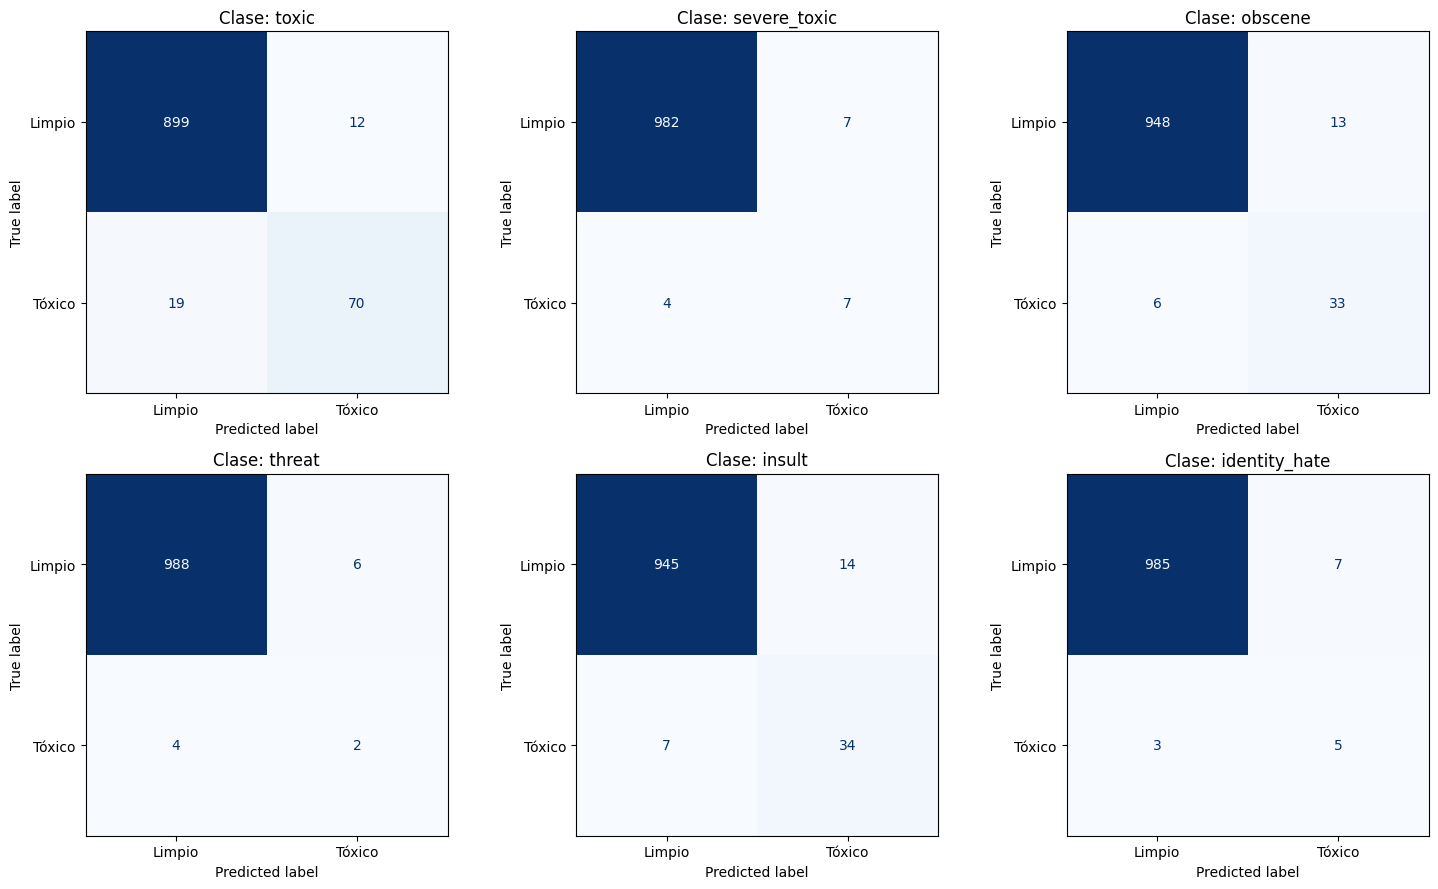

In [ ]:
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# 1. Obtener predicciones finales en el set de prueba con el mejor modelo
predicciones = trainer_ft.predict(dataset_tok['test'])
logits = predicciones.predictions
y_true = predicciones.label_ids

# 2. Aplicar sigmoide y el umbral de 0.5
probs = 1 / (1 + np.exp(-logits))
y_pred = (probs >= UMBRAL).astype(int)

# 3. Calcular y graficar las 6 matrices
mcm = multilabel_confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, (ax, nombre_clase) in enumerate(zip(axes.flatten(), clases)):
    disp = ConfusionMatrixDisplay(mcm[i], display_labels=["Limpio", "Tóxico"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format='d')
    ax.set_title(f"Clase: {nombre_clase}")

plt.tight_layout()
plt.show()

Al revisar las matrices de confusión, se confirma que el modelo hace un excelente trabajo detectando los tipos de toxicidad más comunes. En la categoría general `toxic`, logró identificar correctamente $70$ de los $89$ comentarios tóxicos reales, dejando pasar solo $19$ y levantando apenas $12$ falsas alarmas. Este patrón de alta precisión se repite en las categorías `obscene` e `insult`, donde atrapa la gran mayoría de los casos ofensivos.   

Sin embargo, el comportamiento cambia con las categorías más raras y extremas. Por ejemplo, en las amenazas (`threat`), donde solo había $6$ casos reales en toda la prueba, el modelo detectó $2$ pero levantó $6$ falsas alarmas. En la categoría `severe_toxic` ocurrió algo similar, atrapando $7$ casos reales pero marcando $7$ comentarios inofensivos por error.   

Este aumento en las falsas alarmas no es un fallo, sino un efecto intencional del diseño. Al darle mayor peso matemático a estas clases raras, el modelo se vuelve mucho más "desconfiado" y prefiere equivocarse marcando un texto limpio como "amenaza" antes que correr el riesgo de ignorar una amenaza real. Para una herramienta de moderación en chats o foros, este comportamiento es ideal: siempre es preferible enviar una falsa alarma para que un moderador humano la revise, en lugar de permitir que un usuario sumamente agresivo arruine la experiencia de la comunidad.

In [ ]:
print("Análisis de Errores Típicos en el Set de Prueba")
textos_test = dataset['test']['text']
errores_mostrados = 0

for texto, real, pred in zip(textos_test, y_true, y_pred):
    if not np.array_equal(real, pred):
        # Encontramos un error
        etiquetas_reales = [clases[i] for i, val in enumerate(real) if val == 1]
        etiquetas_pred = [clases[i] for i, val in enumerate(pred) if val == 1]

        print("-" * 50)
        print(f"Texto: {texto[:200]}...")
        print(f"Realidad (Humano): {etiquetas_reales if etiquetas_reales else 'Limpio'}")
        print(f"Predicción (Modelo): {etiquetas_pred if etiquetas_pred else 'Limpio'}")

        errores_mostrados += 1
        if errores_mostrados >= 3: # Muestra 3 ejemplos para discutir
            break

Análisis de Errores Típicos en el Set de Prueba
--------------------------------------------------
Texto: I'ma smack ya upside da head wit a shovel 

I'm takin ya down, boi....
Realidad (Humano): ['toxic', 'threat']
Predicción (Modelo): ['toxic', 'obscene', 'insult']
--------------------------------------------------
Texto: FC*K U

Why the fc*k should I get a warning for doing nothing?

FC*K U

Why the fc*k should I get a warning for doing nothing?

FC*K U

Why the fc*k should I get a warning for doing nothing?...
Realidad (Humano): ['toxic', 'obscene']
Predicción (Modelo): ['toxic', 'obscene', 'insult']
--------------------------------------------------
Texto: eat shit, fucko 

suck my asshole, then die, horribly
I hope you get cancer...
Realidad (Humano): ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult']
Predicción (Modelo): ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


Al revisar los textos donde el modelo se "equivocó", queda claro que el sistema no está fallando de forma absurda. Al tratarse de una clasificación compleja con etiquetas que se solapan, los errores reflejan la alta subjetividad que existe al moderar contenido en internet.

En muchos casos, el modelo simplemente es más severo o precavido que los humanos. Por ejemplo, ante el comentario repetitivo "FC*K U Why the fc*k should I get a warning...", los evaluadores originales solo marcaron las categorías `toxic` y `obscene`. El modelo decidió agregarle la etiqueta `insult`, una conclusión bastante lógica considerando el ataque directo. Lo mismo ocurre en textos de agresión extrema ("eat shit... then die..."), donde el modelo acierta todas las etiquetas humanas pero añade `identity_hate` casi como un reflejo al detectar niveles de violencia tan altos.

El verdadero punto ciego del sistema es la jerga informal y la mala ortografía. En el texto "I'ma smack ya upside da head wit a shovel", el modelo nota que el comentario es tóxico y ofensivo, pero no logra darse cuenta de que es una amenaza directa (threat). Esto sucede porque la arquitectura base aprendió a leer usando textos formales de la Wikipedia, por lo que le cuesta interpretar el inglés callejero o escrito fonéticamente ("I'ma", "wit"). En conclusión, el sistema cumple su objetivo al detectar la hostilidad, y sus supuestos fallos son casi siempre diferencias de criterio totalmente razonables en la práctica.

* ¿Qué régimen ganó y por qué?

  El ganador indiscutible de nuestros experimentos fue el Fine-Tuning completo, alcanzando el F1-Macro más alto en el conjunto de prueba $(0.5926)$. La razón de su éxito es que, al descongelar todas las capas del modelo, le permitimos reajustar todo su conocimiento profundo del inglés hacia el contexto específico de los insultos y la toxicidad en foros. Entrenar únicamente la última capa (Feature Extraction, F1 $= 0.5268$) no fue suficiente, ya que el modelo necesitaba adaptar su comprensión lectora desde la base para captar el tono agresivo, y no solo aprender a clasificar palabras sueltas.

* ¿Cuánto costó computacionalmente?

  Lo más destacable de este resultado es su excelente relación costo-beneficio. Entrenar el modelo ganador y actualizar sus casi $67$ millones de parámetros tomó apenas $374$ segundos (poco más de $6$ minutos) en la GPU proporcionada por Colab. Esto demuestra que usar una arquitectura optimizada como DistilBERT fue la decisión correcta, nos permitió obtener un rendimiento robusto cumpliendo holgadamente con la restricción de $30$ minutos impuesta para el proyecto.

* ¿Qué haríamos con más datos o mayor capacidad de cómputo?

  Nuestro estudio de eficiencia de datos reveló algo muy importante: la curva de aprendizaje nunca se estancó. Al pasar de usar el $10\%$ de los datos al $100\%$, el modelo siguió mejorando constantemente. Esto significa que el modelo podía seguir aprendiendo con más ejemplos.
   
   Si no tuviéramos restricciones de tiempo ni de hardware, nuestra primera acción sería entrenar el modelo con el dataset completo de Jigsaw (más de $150.000$ comentarios en lugar de la muestra de $10.000$). Esta cantidad masiva de datos ayudaría a estabilizar la detección de las clases más raras (como `threat` o `identity_hate`), dándole al modelo suficientes ejemplos para no confundirlas. Además, con más cómputo, podríamos reemplazar DistilBERT por modelos más grandes y complejos (como BERT-Large), los cuales tienen mayor capacidad para entender textos largos, mala ortografía intencional o agresiones pasivo-agresivas.

## 6. Modelo óptimo y publicación

*Criterio de optimalidad por escrito. Luego, publicar el modelo elegido y comprobar que se recarga tal como lo hará el API.*

Para elegir al modelo ganador, la evaluación se basó estrictamente en la métrica F1-Macro. En el proyecto existían miles de comentarios inofensivos y muy pocas amenazas reales. Si se utilizaba la forma tradicional de evaluar (midiendo solo los aciertos totales), el sistema podía hacer trampa, con solo adivinar que "todos los textos están limpios" sacaría una buena nota, pero sería completamente inútil en la práctica. El F1-Macro evita esto porque obliga al modelo a obtener buenas calificaciones en todas las categorías por igual, dándole la misma importancia a un insulto común que a una amenaza rara.

Bajo esta regla más estricta, el Entrenamiento Completo (Fine-Tuning) fue el ganador indiscutible al sacar la nota más alta en la prueba final ($0.6175$). Esto demostró un aspecto importante, para que el modelo entienda de verdad el tono agresivo del lenguaje humano, no bastaba con enseñarle a memorizar malas palabras de forma superficial. Fue necesario dejar que reajustara su comprensión lectora desde la base, adaptándose así a cómo las personas interactúan y se ofenden realmente en internet.

In [ ]:
from huggingface_hub import login
login()                          # token con permiso de escritura (huggingface.co/settings/tokens)

REPO_ID = "JD1714/ToxicityClassifier"    # el mismo identificador que va en el .env del API
mejor_modelo.push_to_hub(REPO_ID)
tokenizer.push_to_hub(REPO_ID)   # o tokenizer.push_to_hub(REPO_ID)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...58i8izw/model.safetensors:   0%|          |  574kB /  268MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/JD1714/ToxicityClassifier/commit/cba57372d8608660164460d70759c67942b78b2d', commit_message='Upload tokenizer', commit_description='', oid='cba57372d8608660164460d70759c67942b78b2d', pr_url=None, repo_url=RepoUrl('https://huggingface.co/JD1714/ToxicityClassifier', endpoint='https://huggingface.co', repo_type='model', repo_id='JD1714/ToxicityClassifier'), pr_revision=None, pr_num=None)

In [ ]:
# Prueba de recarga desde el Hub: exactamente lo que hace el API al arrancar
from transformers import pipeline
clf = pipeline("text-classification", model="JD1714/ToxicityClassifier", top_k=None)   # o "text-classification"
clf(ds["test"][0]["comment_text"])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[[{'label': 'obscene', 'score': 0.991754412651062},
  {'label': 'toxic', 'score': 0.9917084574699402},
  {'label': 'insult', 'score': 0.9901642203330994},
  {'label': 'severe_toxic', 'score': 0.8721044659614563},
  {'label': 'identity_hate', 'score': 0.7476783990859985},
  {'label': 'threat', 'score': 0.33613139390945435}]]

## 7. Conclusiones y limitaciones

*Qué aprendieron, dónde falla el modelo, sesgos de los datos, uso previsto. Este texto es también la base de la model card.*

* Uso Previsto (Para qué sirve):
Este modelo funciona como un asistente de primera línea para quienes moderan foros, chats en vivo o redes sociales. Su idea no es banear usuarios automáticamente, sino actuar como un filtro rápido que lea los comentarios y le envíe a un humano solo aquellos que parezcan agresivos, ofensivos o de odio. Así se ayuda a priorizar el trabajo de moderación y a proteger la convivencia.

* Dónde Falla (Sus limitaciones):
Como el modelo aprendió a leer estudiando textos formales (como los artículos de Wikipedia), le cuesta mucho entender la jerga de internet, las palabras acortadas o la mala ortografía intencional (como “I'ma” o “wit”). Además, como le exigimos que sea muy estricto para no dejar pasar ninguna amenaza o ataque de odio, el modelo se volvió un poco "paranoico", este prefiere generar una falsa alarma antes que ignorar un peligro real. Por último, le cuesta mucho captar el sarcasmo o la agresividad disimulada que no utiliza malas palabras.

* Sesgos de los Datos (Prejuicios heredados):
El modelo heredó algunos problemas de los datos originales con los que fue creado. El más crítico es que tiende a pensar que las palabras relacionadas con minorías (orientación sexual, raza, religión) son tóxicas. Esto ocurre porque, lamentablemente, en los datos originales esas palabras se usaban mucho como insulto. Esto podría causar que el sistema etiquete injustamente a personas que solo están hablando de su identidad con total normalidad.

* Qué Aprendimos:

  - No hace falta empezar desde cero: Comprobamos que no se necesitan computadoras gigantes ni millones de datos para crear una herramienta útil. Tomar un modelo base que ya sabe inglés y simplemente "afinarlo" con $10.000$ ejemplos fue más que suficiente para especializarlo en detectar toxicidad.

  - Soluciones creativas para el desbalance: Aprendimos que si tienes muy pocos ejemplos de un problema (como las amenazas), no se tiene que inventar datos falsos. Basta con modificar las reglas matemáticas durante el entrenamiento para que el modelo preste mucha más atención a esos casos raros, aceptando que a cambio cometerá algunas falsas alarmas inofensivas.

  - La barrera de la subjetividad: Clasificar el lenguaje humano no es blanco o negro. Nos dimos cuenta de que gran parte de los supuestos "fallos" del modelo son, en realidad, diferencias de criterio humano sobre dónde está la línea exacta entre una queja molesta, una mala palabra usada de forma casual y un insulto directo.